# Physics-Based Modeling & Monte Carlo Uncertainty Analysis of the 2010 Mount Merapi Rapid Lava Dome Extrusion

**Author:** Tangguh Sudira Oktafiandariento  
**Affiliation:** M.Sc. Candidate in Physics (Geoscience), Universitas Gadjah Mada (UGM) · LPDP Awardee  
**Domain:** Computational Volcanology · Continuum Mechanics · Uncertainty Quantification

---

### Executive Overview
Between 1 and 4 November 2010, Mount Merapi (Java, Indonesia) extruded a basaltic-andesite lava dome of $V_{\text{dome}} \approx 5.0 \times 10^6\text{ m}^3$ at a mean rate of $Q = 25\text{ m}^3/\text{s}$—**10.4× faster** than its 2006 eruption—immediately preceding the catastrophic VEI 4 paroxysmal dome explosion on 5 November 2010 (Pallister et al., 2013; Surono et al., 2012).

This notebook integrates three coupled continuum conservation laws with solidification and probabilistic modeling:
1. **Mass Conservation (1D Conduit Kinematics):** Mass flux $\dot{M}$, cumulative dome growth, and mean ascent velocity $U$.
2. **Momentum Conservation (Cauchy $\rightarrow$ Hagen–Poiseuille):** Effective magma viscosity $\eta$, wall shear stress $\tau_w$, conduit transit time $t_{\text{ascent}}$, plus quantitative steady-state ($\tau_1$) and lubrication ($\text{Re}\cdot R_c/L$) validation.
3. **Thermal Energy, Viscous Dissipation & Second Law (Clausius–Duhem):** Péclet number $\text{Pe}$, conductive cooling skin $\delta_T$ (fresh vs. hydrothermally altered andesite), shear heating $P_{\text{visc}}$, and entropy production $\dot{S}_{\text{gen}}$.
4. **Stefan Solidification & Temperature-Dependent Viscosity Feedback $\eta(T)$:** Solidified crust thickness $s(t)$, critical freezing radius $R_{c,\text{crit}}$, and discharge reduction $Q/Q_0$ across eruption regimes.
5. **Deterministic Sensitivity & Monte Carlo Uncertainty Analysis ($N = 20{,}000$):** Exact variance decomposition of $\text{var}(\ln\eta)$ and probabilistic validation against petrological amphibole breakdown kinetics ($P(t_{\text{ascent}} < 48\text{ h})$).

In [1]:
import os
import numpy as np
from scipy.special import erf
from scipy.optimize import brentq
import matplotlib.pyplot as plt

# ==============================================================================
# CENTRALIZED PHYSICAL PARAMETERS (SI UNITS) & PRIMARY LITERATURE CITATIONS
# ==============================================================================
PARAMS = {
    # Extrusion & Dome Geometry [Pallister et al., 2013; Komorowski et al., 2013]
    "Q_2010": 25.0,           # m^3/s, mean extrusion rate 1-4 Nov 2010 (range 20-35)
    "Q_6Nov": 35.0,           # m^3/s, post-paroxysmal extrusion rate 6 Nov 2010
    "Q_2006": 2.4,            # m^3/s, mean extrusion rate May-Jun 2006 [Ratdomopurbo et al., 2013]
    "Q_typ": 0.15,            # m^3/s, typical 1984-1996 regime [Hammer et al., 2000]
    "V_dome": 5.0e6,          # m^3, new dome volume 1-4 Nov 2010 [Pallister et al., 2013]
    "rho_m": 2500.0,          # kg/m^3, dense juvenile dome bulk density [Komorowski et al., 2013]

    # Shallow Conduit Geometry & Overpressure [Costa et al., 2013; Surono et al., 2012]
    "R_c": 15.0,              # m, effective cylindrical conduit radius (range 10-25 m)
    "L": 2000.0,              # m, shallow conduit length (range 1500-3000 m)
    "dP_min": 10.0e6,         # Pa, lower bound non-hydrostatic overpressure
    "dP_ref": 15.0e6,         # Pa, reference overpressure (G = 7.5 kPa/m)
    "dP_max": 20.0e6,         # Pa, upper bound overpressure

    # Thermal & Petrological Properties [Surono et al., 2012; Heap et al., 2020]
    "T_m_C": 1000.0,          # degC, pre-eruptive magma temperature (1273.15 K)
    "T_h_C": 300.0,           # degC, far-field host rock temperature (573.15 K)
    "T_s_C": 850.0,           # degC, effective andesite solidus temperature
    "kappa_fresh": 0.70e-6,   # m^2/s, fresh dome andesite MU_5B4-5B8 [Heap et al., 2020]
    "k_fresh": 1.43,          # W/(m*K), fresh dome andesite [Heap et al., 2020]
    "kappa_alt": 0.47e-6,     # m^2/s, hydrothermally altered MHA1-MHA2 [Heap et al., 2020]
    "k_alt": 0.85,            # W/(m*K), hydrothermally altered andesite [Heap et al., 2020]
    "c_p": 1000.0,            # J/(kg*K), specific heat capacity [Heap et al., 2020]
    "L_f": 3.0e5,             # J/kg, latent heat of crystallization [Turcotte & Schubert, 2014]
    "beta_visc": 0.02,        # K^-1, thermal viscosity sensitivity coefficient
    "t_amphibole_h": 48.0,    # hours, amphibole breakdown rim threshold [Rutherford, 2008; Costa et al., 2013]
}

# UGM Navy + Merapi Crimson + UGM Gold Color Palette
UGM_BLUE   = "#0B396F"
UGM_GOLD   = "#B38F00"
MERAPI_RED = "#8B1E0F"
SLATE_DARK = "#2C3E50"
TEAL_ACC   = "#1E6B7B"
SOFT_GOLD  = "#FEF9E7"
SOFT_BLUE  = "#F0F5FA"
SOFT_RED   = "#FDF2F0"

print("Centralized parameter dictionary initialized successfully.")
print(f"Reference Case: Q = {PARAMS['Q_2010']} m^3/s, R_c = {PARAMS['R_c']} m, L = {PARAMS['L']} m, dP = {PARAMS['dP_ref']/1e6:.0f} MPa")

Centralized parameter dictionary initialized successfully.
Reference Case: Q = 25.0 m^3/s, R_c = 15.0 m, L = 2000.0 m, dP = 15 MPa


## 1. Mass Conservation & Conduit Kinematics

Under quasi-steady, incompressible 1D axial flow in a cylindrical conduit of cross-sectional area $A_c = \pi R_c^2$:

$$\frac{\partial \rho}{\partial t} + \nabla \cdot (\rho \mathbf{v}) = 0 \quad \Longrightarrow \quad \dot{M} = \rho_m Q = \rho_m (\pi R_c^2) U, \qquad U = \frac{Q}{\pi R_c^2}$$

Conduit Area A_c       : 706.86 m^2
Mass Flux M_dot (2010) : 6.25e+04 kg/s (5.40e+09 kg/day)
Total Dome Mass M_dome : 1.25e+10 kg (12.5 Mt) in t_eff = 55.56 h (2.31 days)
Mean Ascent Velocity U : 3.54 cm/s (127.32 m/h)
Kinematic Surge Factor : 10.4x vs 2006 | 166.7x vs 1984-1996 typical


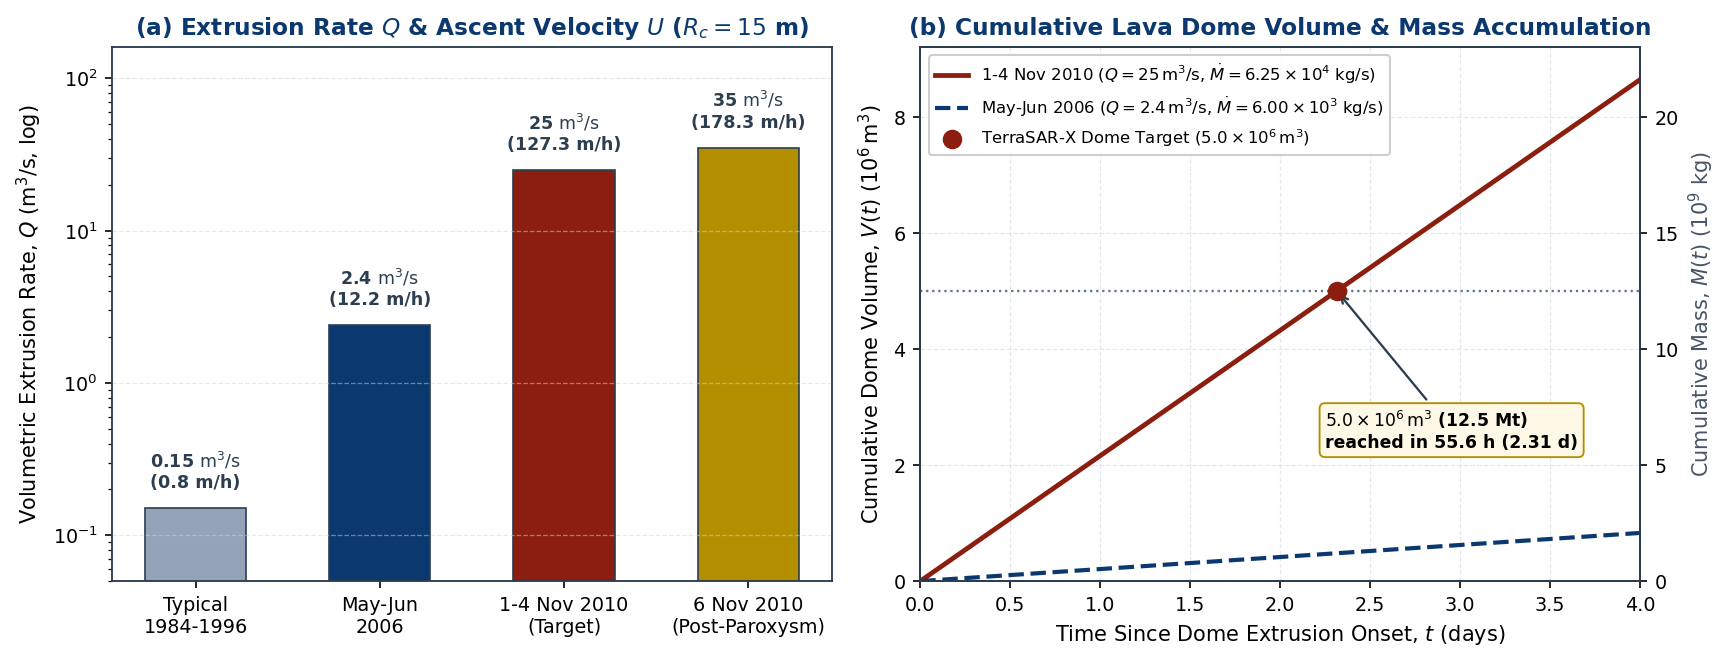

In [2]:
# 1. Mass Conservation & Conduit Kinematics
R_c = PARAMS["R_c"]
rho_m = PARAMS["rho_m"]
Q_2010 = PARAMS["Q_2010"]
V_dome = PARAMS["V_dome"]

A_c = np.pi * R_c**2
M_dot_2010 = rho_m * Q_2010
M_dome = rho_m * V_dome
t_eff_s = V_dome / Q_2010
t_eff_h = t_eff_s / 3600.0

U_2010 = Q_2010 / A_c
U_2006 = PARAMS["Q_2006"] / A_c
U_typ  = PARAMS["Q_typ"] / A_c
U_6Nov = PARAMS["Q_6Nov"] / A_c

print(f"Conduit Area A_c       : {A_c:.2f} m^2")
print(f"Mass Flux M_dot (2010) : {M_dot_2010:.2e} kg/s ({M_dot_2010*86400:.2e} kg/day)")
print(f"Total Dome Mass M_dome : {M_dome:.2e} kg (12.5 Mt) in t_eff = {t_eff_h:.2f} h ({t_eff_h/24:.2f} days)")
print(f"Mean Ascent Velocity U : {U_2010*100:.2f} cm/s ({U_2010*3600:.2f} m/h)")
print(f"Kinematic Surge Factor : {Q_2010/PARAMS['Q_2006']:.1f}x vs 2006 | {Q_2010/PARAMS['Q_typ']:.1f}x vs 1984-1996 typical")

# --- Figure 1: Extrusion Regimes & Cumulative Dome Growth (Zero Overlap) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.6, 4.5), dpi=220)

regimes = ["Typical\n1984-1996", "May-Jun\n2006", "1-4 Nov 2010\n(Target)", "6 Nov 2010\n(Post-Paroxysm)"]
Q_vals = [PARAMS["Q_typ"], PARAMS["Q_2006"], Q_2010, PARAMS["Q_6Nov"]]
U_mh   = [q / A_c * 3600.0 for q in Q_vals]
colors = ["#94A3B8", UGM_BLUE, MERAPI_RED, UGM_GOLD]

bars = ax1.bar(regimes, Q_vals, color=colors, width=0.55, edgecolor=SLATE_DARK, linewidth=0.8)
ax1.set_yscale("log")
ax1.set_ylim(0.05, 160)
ax1.set_ylabel(r"Volumetric Extrusion Rate, $Q$ ($\mathrm{m^3/s}$, log)")
ax1.set_title(r"(a) Extrusion Rate $Q$ & Ascent Velocity $U$ ($R_c = 15$ m)", color=UGM_BLUE)
ax1.grid(axis="y", alpha=0.5)
for bar, q, u in zip(bars, Q_vals, U_mh):
    ax1.text(bar.get_x() + bar.get_width()/2, q * 1.28,
             f"{q:g} $\\mathrm{{m^3/s}}$\n({u:.1f} m/h)",
             ha="center", va="bottom", fontsize=8.4, fontweight="bold", color=SLATE_DARK)

t_days = np.linspace(0, 4.0, 200)
V_2006_curve = PARAMS["Q_2006"] * t_days * 86400 / 1e6

ax2.plot(t_days, Q_2010 * t_days * 86400 / 1e6, color=MERAPI_RED, lw=2.3,
         label=r"1-4 Nov 2010 ($Q = 25\,\mathrm{m^3/s}$, $\dot{M} = 6.25\times10^4$ kg/s)")
ax2.plot(t_days, V_2006_curve, color=UGM_BLUE, lw=2.0, ls="--",
         label=r"May-Jun 2006 ($Q = 2.4\,\mathrm{m^3/s}$, $\dot{M} = 6.00\times10^3$ kg/s)")
ax2.axhline(5.0, color="#64748B", ls=":", lw=1.1)
ax2.scatter([t_eff_h/24], [5.0], color=MERAPI_RED, s=70, zorder=5,
            label=r"TerraSAR-X Dome Target ($5.0\times10^6\,\mathrm{m^3}$)")
ax2.annotate(f"$5.0\\times10^6\\,\\mathrm{{m^3}}$ (12.5 Mt)\nreached in {t_eff_h:.1f} h ({t_eff_h/24:.2f} d)",
             xy=(t_eff_h/24, 5.0), xytext=(2.25, 2.3),
             arrowprops=dict(arrowstyle="->", color=SLATE_DARK, lw=1.1),
             fontsize=8.3, fontweight="bold", bbox=dict(boxstyle="round,pad=0.32", fc=SOFT_GOLD, ec=UGM_GOLD, lw=0.9))
ax2.set_xlim(0, 4.0)
ax2.set_ylim(0, 9.2)
ax2.set_xlabel("Time Since Dome Extrusion Onset, $t$ (days)")
ax2.set_ylabel(r"Cumulative Dome Volume, $V(t)$ ($10^6\,\mathrm{m^3}$)")
ax2.set_title("(b) Cumulative Lava Dome Volume & Mass Accumulation", color=UGM_BLUE)
ax2.grid(alpha=0.5)
ax2.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.95, fontsize=7.9)

ax2_r = ax2.twinx()
ax2_r.set_ylim(0, 9.2 * rho_m / 1e3)
ax2_r.set_ylabel(r"Cumulative Mass, $M(t)$ ($10^9$ kg)", color="#475569")

plt.tight_layout()
os.makedirs("figs", exist_ok=True); plt.savefig("figs/fig1_extrusion_kinematics.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Momentum Conservation: Cauchy Equation to Hagen–Poiseuille Flow & Validation

Reducing the Cauchy linear momentum balance $\rho D\mathbf{v}/Dt = -\nabla p + \nabla\cdot\boldsymbol{\tau} + \rho\mathbf{g}$ for steady, axisymmetric, creeping laminar Newtonian flow in a vertical cylindrical conduit ($\text{Re} \ll 1$) yields:

$$v_z(r) = 2U\left(1 - \frac{r^2}{R_c^2}\right), \quad \tau_w = \frac{R_c \Delta P}{2L}, \quad \eta = \frac{\pi R_c^4 \Delta P}{8 Q L}, \quad t_{\text{ascent}} = \frac{L}{U}$$

We verify steady-state relaxation ($\tau_1 = R_c^2 / (\alpha_1^2 \nu)$) and the reduced lubrication Reynolds number ($\text{Re}\cdot R_c/L \ll 1$).

Effective Viscosity eta    : 3.976e+06 to 7.952e+06 Pa*s (ref 5.964e+06 Pa*s)
Reynolds Number Re         : 3.34e-04 to 6.67e-04 << 1 (creeping laminar)
Wall Shear Stress tau_w    : 37.50 to 75.00 kPa (ref 56.25 kPa)
Wall Shear Rate gamma_w    : 9.43e-03 s^-1
Transit Time t_ascent (2010): 15.71 h (core: 7.85 h) vs 2006: 163.62 h
Steady Relaxation tau_1    : 16.31 ms (tau_1/t_ascent = 2.88e-07 << 1)
Lubrication Re*(R_c/L)     : 3.34e-06 << 1 (aspect ratio R_c/L = 0.0075)


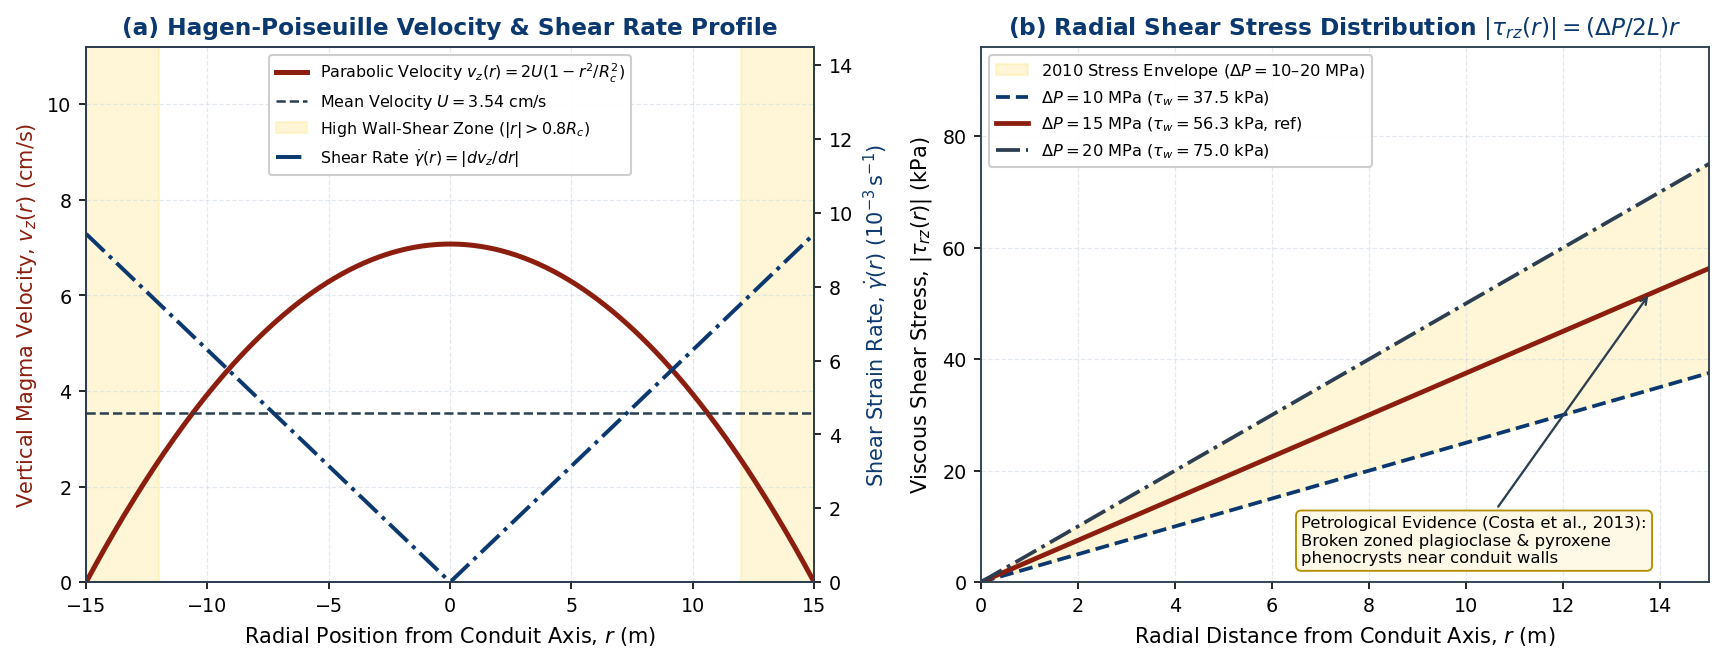

In [3]:
# 2. Momentum Conservation (Hagen-Poiseuille) & Quantitative Assumption Checks
L = PARAMS["L"]
dP_min, dP_ref, dP_max = PARAMS["dP_min"], PARAMS["dP_ref"], PARAMS["dP_max"]

eta_min = np.pi * R_c**4 * dP_min / (8 * Q_2010 * L)
eta_ref = np.pi * R_c**4 * dP_ref / (8 * Q_2010 * L)
eta_max = np.pi * R_c**4 * dP_max / (8 * Q_2010 * L)

Re_min = rho_m * U_2010 * (2 * R_c) / eta_max
Re_ref = rho_m * U_2010 * (2 * R_c) / eta_ref
Re_max = rho_m * U_2010 * (2 * R_c) / eta_min

tau_w_min = R_c * dP_min / (2 * L)
tau_w_ref = R_c * dP_ref / (2 * L)
tau_w_max = R_c * dP_max / (2 * L)
gamma_dot_w = 4 * U_2010 / R_c

t_ascent_s = L / U_2010
t_ascent_h = t_ascent_s / 3600.0
t_core_h   = t_ascent_h / 2.0
t_ascent_2006_h = (L / U_2006) / 3600.0

alpha_1 = 2.4048255577
nu_ref = eta_ref / rho_m
tau_1 = R_c**2 / (alpha_1**2 * nu_ref)
aspect_ratio = R_c / L
Re_lub = Re_ref * aspect_ratio

print(f"Effective Viscosity eta    : {eta_min:.3e} to {eta_max:.3e} Pa*s (ref {eta_ref:.3e} Pa*s)")
print(f"Reynolds Number Re         : {Re_min:.2e} to {Re_max:.2e} << 1 (creeping laminar)")
print(f"Wall Shear Stress tau_w    : {tau_w_min/1e3:.2f} to {tau_w_max/1e3:.2f} kPa (ref {tau_w_ref/1e3:.2f} kPa)")
print(f"Wall Shear Rate gamma_w    : {gamma_dot_w:.2e} s^-1")
print(f"Transit Time t_ascent (2010): {t_ascent_h:.2f} h (core: {t_core_h:.2f} h) vs 2006: {t_ascent_2006_h:.2f} h")
print(f"Steady Relaxation tau_1    : {tau_1*1e3:.2f} ms (tau_1/t_ascent = {tau_1/t_ascent_s:.2e} << 1)")
print(f"Lubrication Re*(R_c/L)     : {Re_lub:.2e} << 1 (aspect ratio R_c/L = {aspect_ratio:.4f})")

# --- Figure 2: Velocity Profile & Shear Stress Distribution (Zero Overlap) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.6, 4.5), dpi=220)

r_full = np.linspace(-R_c, R_c, 300)
vz_cm = 2 * U_2010 * (1 - (r_full / R_c)**2) * 100.0
gdot_m3 = 4 * U_2010 / (R_c**2) * np.abs(r_full) * 1e3

ax1.plot(r_full, vz_cm, color=MERAPI_RED, lw=2.4, label=r"Parabolic Velocity $v_z(r) = 2U(1-r^2/R_c^2)$")
ax1.axhline(U_2010*100, color=SLATE_DARK, ls="--", lw=1.2, label=f"Mean Velocity $U = {U_2010*100:.2f}$ cm/s")
ax1.axvspan(0.8*R_c, R_c, color="#FDE68A", alpha=0.35, label=r"High Wall-Shear Zone ($|r| > 0.8 R_c$)")
ax1.axvspan(-R_c, -0.8*R_c, color="#FDE68A", alpha=0.35)
ax1.set_xlim(-R_c, R_c)
ax1.set_ylim(0, 11.2)
ax1.set_xlabel("Radial Position from Conduit Axis, $r$ (m)")
ax1.set_ylabel("Vertical Magma Velocity, $v_z(r)$ (cm/s)", color=MERAPI_RED)
ax1.set_title("(a) Hagen-Poiseuille Velocity & Shear Rate Profile", color=UGM_BLUE)
ax1.grid(alpha=0.5)

ax1_r = ax1.twinx()
ax1_r.plot(r_full, gdot_m3, color=UGM_BLUE, lw=1.9, ls="-.", label=r"Shear Rate $\dot{\gamma}(r) = |dv_z/dr|$")
ax1_r.set_ylim(0, 14.5)
ax1_r.set_ylabel(r"Shear Strain Rate, $\dot{\gamma}(r)$ ($10^{-3}\,\mathrm{s^{-1}}$)", color=UGM_BLUE)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1_r.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", fontsize=7.6, frameon=True, facecolor="white", framealpha=0.95)

r_pos = np.linspace(0, R_c, 200)
tau_10 = (dP_min / (2 * L)) * r_pos / 1e3
tau_15 = (dP_ref / (2 * L)) * r_pos / 1e3
tau_20 = (dP_max / (2 * L)) * r_pos / 1e3

ax2.fill_between(r_pos, tau_10, tau_20, color="#FDE68A", alpha=0.35, label=r"2010 Stress Envelope ($\Delta P = 10$–$20$ MPa)")
ax2.plot(r_pos, tau_10, color=UGM_BLUE, lw=1.8, ls="--", label=r"$\Delta P = 10$ MPa ($\tau_w = 37.5$ kPa)")
ax2.plot(r_pos, tau_15, color=MERAPI_RED, lw=2.3, label=r"$\Delta P = 15$ MPa ($\tau_w = 56.3$ kPa, ref)")
ax2.plot(r_pos, tau_20, color=SLATE_DARK, lw=1.8, ls="-.", label=r"$\Delta P = 20$ MPa ($\tau_w = 75.0$ kPa)")
ax2.annotate("Petrological Evidence (Costa et al., 2013):\nBroken zoned plagioclase & pyroxene\nphenocrysts near conduit walls",
             xy=(13.8, 52), xytext=(6.6, 3.5),
             arrowprops=dict(arrowstyle="->", color=SLATE_DARK, lw=1.1),
             fontsize=7.9, bbox=dict(boxstyle="round,pad=0.32", fc=SOFT_GOLD, ec=UGM_GOLD, lw=0.9))
ax2.set_xlim(0, R_c)
ax2.set_ylim(0, 96)
ax2.set_xlabel("Radial Distance from Conduit Axis, $r$ (m)")
ax2.set_ylabel(r"Viscous Shear Stress, $|\tau_{rz}(r)|$ (kPa)")
ax2.set_title(r"(b) Radial Shear Stress Distribution $|\tau_{rz}(r)| = (\Delta P / 2L)r$", color=UGM_BLUE)
ax2.grid(alpha=0.5)
ax2.legend(loc="upper left", fontsize=7.8, frameon=True, facecolor="white", framealpha=0.95)

plt.tight_layout()
os.makedirs("figs", exist_ok=True); plt.savefig("figs/fig2_poiseuille_shear.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Thermal Energy Balance, Viscous Dissipation & Second Law Entropy

Comparing axial thermal advection against radial conduction yields the Péclet ($\text{Pe}$) and Graetz ($\text{Gz}$) numbers:

$$\rho_m c_p \frac{DT}{Dt} = \nabla \cdot (k \nabla T) + \Phi, \qquad \text{Pe} = \frac{U R_c}{\kappa}, \quad \delta_T = \sqrt{\kappa t_{\text{ascent}}}, \quad \dot{S}_{\text{gen,visc}} = \frac{Q \Delta P}{T_m} > 0$$

Radial Diffusion Time tau_dif : 10.19 years
Peclet Number Pe (fresh/alt)  : 7.58e+05 / 1.13e+06 >> 1 (Gz = 5684)
Cooling Skin delta_T (2010)   : 19.90 cm fresh (1.33% R_c) | 16.30 cm altered (1.09% R_c)
Cooling Skin delta_T (2006)   : 64.2 cm | Adiabatic Core Fraction (2010): 97.36%
Viscous Dissipation P_visc    : 250-500 MW (ref 375 MW), Wall Phi_w = 353.7-707.4 W/m^3
Shear Heating dT_visc         : 4.0-8.0 K | Entropy Prod S_gen = 196.4-392.7 kW/K > 0
Advective Enthalpy H_adv      : 79.69 GW vs Wall Conduction P_cond = 948.36 MW (ratio 84x)


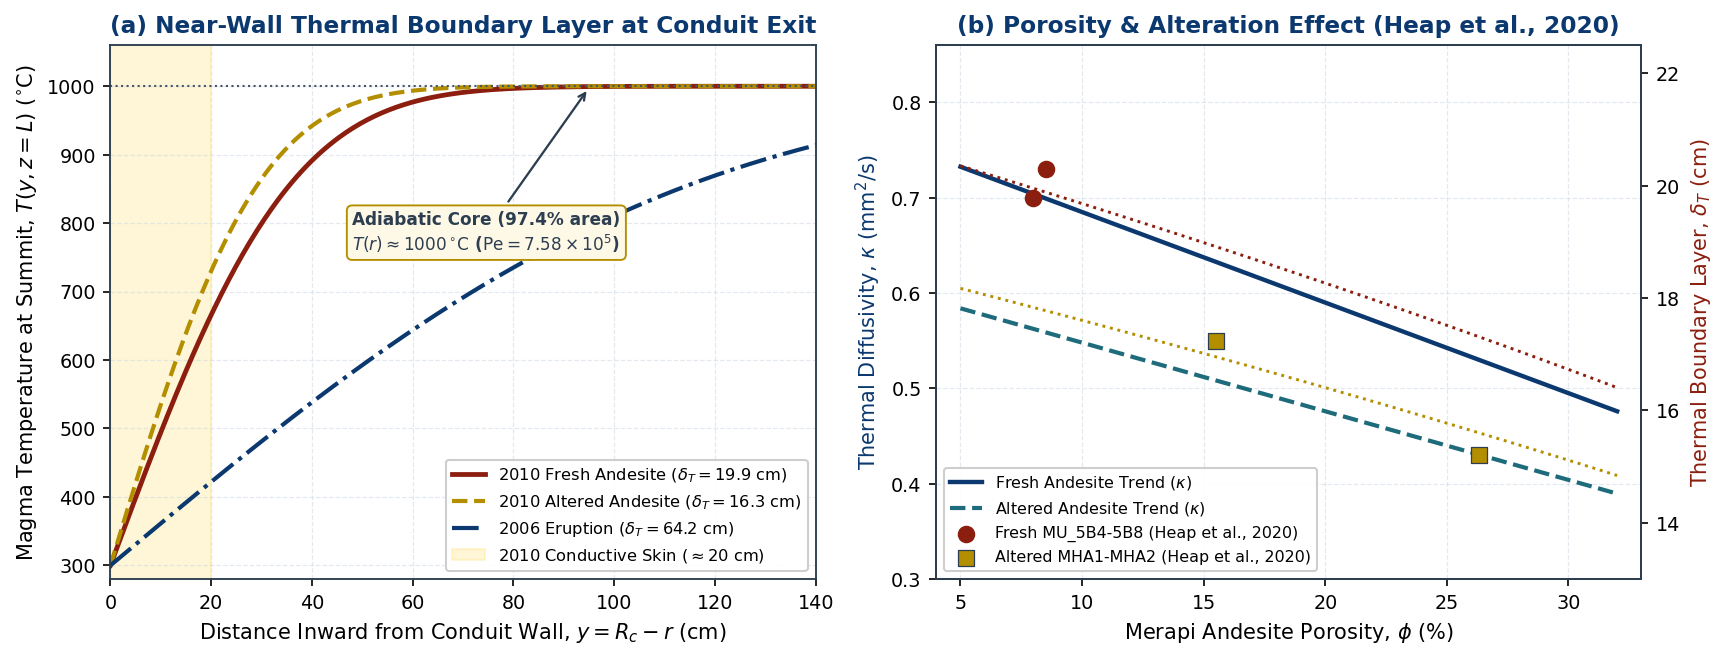

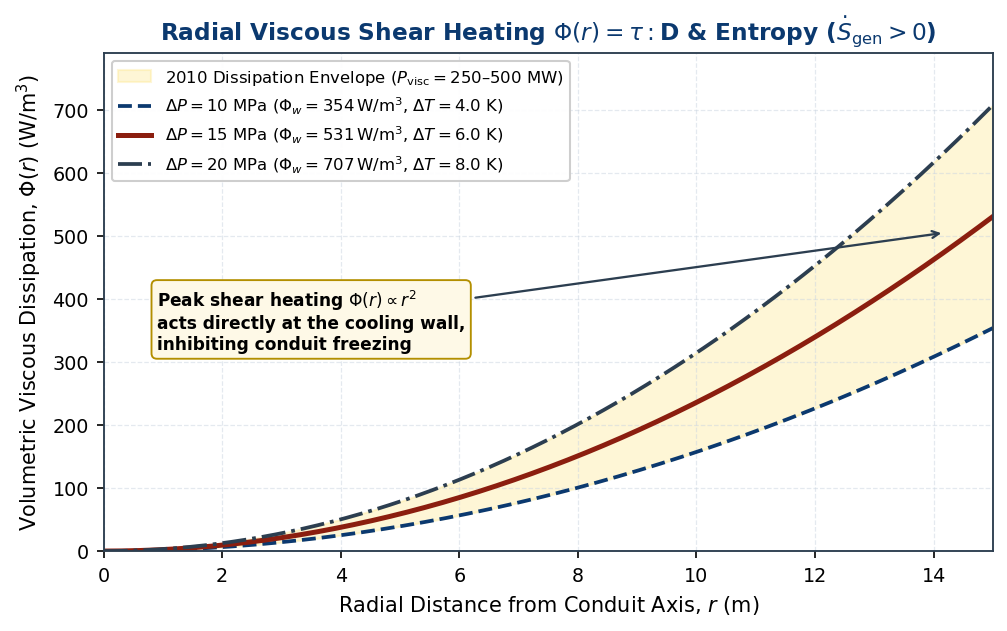

In [4]:
# 3. Thermal Energy Balance, Alteration Effect, Viscous Dissipation & Entropy
kappa_fresh = PARAMS["kappa_fresh"]
kappa_alt   = PARAMS["kappa_alt"]
k_fresh     = PARAMS["k_fresh"]
c_p         = PARAMS["c_p"]
T_m_C       = PARAMS["T_m_C"]
T_h_C       = PARAMS["T_h_C"]
T_m_K       = T_m_C + 273.15

tau_dif_s   = R_c**2 / kappa_fresh
Pe_fresh    = U_2010 * R_c / kappa_fresh
Pe_alt      = U_2010 * R_c / kappa_alt
Gz_fresh    = tau_dif_s / t_ascent_s

delta_T_fresh = np.sqrt(kappa_fresh * t_ascent_s)
delta_T_alt   = np.sqrt(kappa_alt * t_ascent_s)
delta_T_2006  = np.sqrt(kappa_fresh * (L / U_2006))
f_core        = (1.0 - delta_T_fresh / R_c)**2

P_visc_min  = Q_2010 * dP_min
P_visc_ref  = Q_2010 * dP_ref
P_visc_max  = Q_2010 * dP_max
Phi_w_min   = tau_w_min * gamma_dot_w
Phi_w_max   = tau_w_max * gamma_dot_w
dT_visc_min = dP_min / (rho_m * c_p)
dT_visc_max = dP_max / (rho_m * c_p)
S_gen_min   = P_visc_min / T_m_K
S_gen_max   = P_visc_max / T_m_K

H_adv       = M_dot_2010 * (c_p * (T_m_C - 25.0) + PARAMS["L_f"])
P_cond      = 2 * np.pi * R_c * L * k_fresh * (T_m_C - T_h_C) / delta_T_fresh

print(f"Radial Diffusion Time tau_dif : {tau_dif_s/(365.25*86400):.2f} years")
print(f"Peclet Number Pe (fresh/alt)  : {Pe_fresh:.2e} / {Pe_alt:.2e} >> 1 (Gz = {Gz_fresh:.0f})")
print(f"Cooling Skin delta_T (2010)   : {delta_T_fresh*100:.2f} cm fresh ({delta_T_fresh/R_c*100:.2f}% R_c) | {delta_T_alt*100:.2f} cm altered ({delta_T_alt/R_c*100:.2f}% R_c)")
print(f"Cooling Skin delta_T (2006)   : {delta_T_2006*100:.1f} cm | Adiabatic Core Fraction (2010): {f_core*100:.2f}%")
print(f"Viscous Dissipation P_visc    : {P_visc_min/1e6:.0f}-{P_visc_max/1e6:.0f} MW (ref {P_visc_ref/1e6:.0f} MW), Wall Phi_w = {Phi_w_min:.1f}-{Phi_w_max:.1f} W/m^3")
print(f"Shear Heating dT_visc         : {dT_visc_min:.1f}-{dT_visc_max:.1f} K | Entropy Prod S_gen = {S_gen_min/1e3:.1f}-{S_gen_max/1e3:.1f} kW/K > 0")
print(f"Advective Enthalpy H_adv      : {H_adv/1e9:.2f} GW vs Wall Conduction P_cond = {P_cond/1e6:.2f} MW (ratio {H_adv/P_cond:.0f}x)")

# --- Figure 3: Thermal Boundary Layer & Porosity/Alteration Effect (Zero Overlap) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.6, 4.5), dpi=220)

y_cm = np.linspace(0, 140, 300)
y_m  = y_cm / 100.0
T_2010_fresh = T_h_C + (T_m_C - T_h_C) * erf(y_m / (2 * delta_T_fresh))
T_2010_alt   = T_h_C + (T_m_C - T_h_C) * erf(y_m / (2 * delta_T_alt))
T_2006_fresh = T_h_C + (T_m_C - T_h_C) * erf(y_m / (2 * delta_T_2006))

ax1.plot(y_cm, T_2010_fresh, color=MERAPI_RED, lw=2.3, label=r"2010 Fresh Andesite ($\delta_T = 19.9$ cm)")
ax1.plot(y_cm, T_2010_alt, color=UGM_GOLD, lw=2.0, ls="--", label=r"2010 Altered Andesite ($\delta_T = 16.3$ cm)")
ax1.plot(y_cm, T_2006_fresh, color=UGM_BLUE, lw=2.0, ls="-.", label=r"2006 Eruption ($\delta_T = 64.2$ cm)")
ax1.axvspan(0, delta_T_fresh*100, color="#FDE68A", alpha=0.35, label=r"2010 Conductive Skin ($\approx 20$ cm)")
ax1.axhline(1000, color="#475569", ls=":", lw=1.0)
ax1.annotate("Adiabatic Core (97.4% area)\n" + r"$T(r) \approx 1000\,^{\circ}\mathrm{C}$ ($\mathrm{Pe} = 7.58\times10^5$)",
             xy=(95, 998), xytext=(48, 760),
             arrowprops=dict(arrowstyle="->", color=SLATE_DARK, lw=1.1),
             fontsize=8.1, fontweight="bold", color=SLATE_DARK,
             bbox=dict(boxstyle="round,pad=0.32", fc=SOFT_GOLD, ec=UGM_GOLD, lw=0.9))
ax1.set_xlim(0, 140)
ax1.set_ylim(280, 1060)
ax1.set_xlabel("Distance Inward from Conduit Wall, $y = R_c - r$ (cm)")
ax1.set_ylabel(r"Magma Temperature at Summit, $T(y, z=L)$ ($^{\circ}\mathrm{C}$)")
ax1.set_title("(a) Near-Wall Thermal Boundary Layer at Conduit Exit", color=UGM_BLUE)
ax1.grid(alpha=0.5)
ax1.legend(loc="lower right", fontsize=7.8, frameon=True, facecolor="white", framealpha=0.95)

phi_pct = np.linspace(5, 32, 100)
kappa_fresh_trend = 0.78 - 0.0095 * phi_pct
kappa_alt_trend   = 0.62 - 0.0072 * phi_pct
dT_fresh_trend    = np.sqrt(kappa_fresh_trend * 1e-6 * t_ascent_s) * 100
dT_alt_trend      = np.sqrt(kappa_alt_trend * 1e-6 * t_ascent_s) * 100

ax2.plot(phi_pct, kappa_fresh_trend, color=UGM_BLUE, lw=2.1, label=r"Fresh Andesite Trend ($\kappa$)")
ax2.plot(phi_pct, kappa_alt_trend, color=TEAL_ACC, lw=2.0, ls="--", label=r"Altered Andesite Trend ($\kappa$)")
ax2.scatter([8.0, 8.5], [0.70, 0.73], color=MERAPI_RED, s=55, zorder=5, label="Fresh MU_5B4-5B8 (Heap et al., 2020)")
ax2.scatter([15.5, 26.3], [0.55, 0.43], color=UGM_GOLD, marker="s", s=55, zorder=5, edgecolor=SLATE_DARK, lw=0.6, label="Altered MHA1-MHA2 (Heap et al., 2020)")
ax2.set_xlim(4, 33)
ax2.set_ylim(0.30, 0.86)
ax2.set_xlabel(r"Merapi Andesite Porosity, $\phi$ (%)")
ax2.set_ylabel(r"Thermal Diffusivity, $\kappa$ ($\mathrm{mm^2/s}$)", color=UGM_BLUE)
ax2.set_title("(b) Porosity & Alteration Effect (Heap et al., 2020)", color=UGM_BLUE)
ax2.grid(alpha=0.5)

ax2_r = ax2.twinx()
ax2_r.plot(phi_pct, dT_fresh_trend, color=MERAPI_RED, lw=1.4, ls=":", label=r"Skin $\delta_T$ (fresh, cm)")
ax2_r.plot(phi_pct, dT_alt_trend, color=UGM_GOLD, lw=1.4, ls=":", label=r"Skin $\delta_T$ (altered, cm)")
ax2_r.set_ylim(13.0, 22.5)
ax2_r.set_ylabel(r"Thermal Boundary Layer, $\delta_T$ (cm)", color=MERAPI_RED)

h1, l1 = ax2.get_legend_handles_labels()
ax2.legend(h1, l1, loc="lower left", fontsize=7.6, frameon=True, facecolor="white", framealpha=0.95)

plt.tight_layout()
os.makedirs("figs", exist_ok=True); plt.savefig("figs/fig3_thermal_alteration.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Figure 4: Radial Viscous Dissipation Profile (Zero Overlap) ---
fig, ax = plt.subplots(figsize=(6.8, 4.3), dpi=220)
r_pos = np.linspace(0, R_c, 250)
Phi_10 = (1.0 / (4 * eta_min)) * (dP_min / L)**2 * r_pos**2
Phi_15 = (1.0 / (4 * eta_ref)) * (dP_ref / L)**2 * r_pos**2
Phi_20 = (1.0 / (4 * eta_max)) * (dP_max / L)**2 * r_pos**2

ax.fill_between(r_pos, Phi_10, Phi_20, color="#FDE68A", alpha=0.35, label=r"2010 Dissipation Envelope ($P_{\mathrm{visc}} = 250$–$500$ MW)")
ax.plot(r_pos, Phi_10, color=UGM_BLUE, lw=1.8, ls="--", label=r"$\Delta P = 10$ MPa ($\Phi_w = 354\,\mathrm{W/m^3}$, $\Delta T = 4.0$ K)")
ax.plot(r_pos, Phi_15, color=MERAPI_RED, lw=2.4, label=r"$\Delta P = 15$ MPa ($\Phi_w = 531\,\mathrm{W/m^3}$, $\Delta T = 6.0$ K)")
ax.plot(r_pos, Phi_20, color=SLATE_DARK, lw=1.8, ls="-.", label=r"$\Delta P = 20$ MPa ($\Phi_w = 707\,\mathrm{W/m^3}$, $\Delta T = 8.0$ K)")
ax.annotate("Peak shear heating " + r"$\Phi(r) \propto r^2$" + "\nacts directly at the cooling wall,\ninhibiting conduit freezing",
            xy=(14.2, 505), xytext=(0.9, 320),
            arrowprops=dict(arrowstyle="->", color=SLATE_DARK, lw=1.1),
            fontsize=8.2, fontweight="bold", bbox=dict(boxstyle="round,pad=0.32", fc=SOFT_GOLD, ec=UGM_GOLD, lw=0.9))
ax.set_xlim(0, R_c)
ax.set_ylim(0, 790)
ax.set_xlabel("Radial Distance from Conduit Axis, $r$ (m)")
ax.set_ylabel(r"Volumetric Viscous Dissipation, $\Phi(r)$ ($\mathrm{W/m^3}$)")
ax.set_title(r"Radial Viscous Shear Heating $\Phi(r) = \tau:\mathbf{D}$ & Entropy ($\dot{S}_{\mathrm{gen}} > 0$)", color=UGM_BLUE)
ax.grid(alpha=0.5)
ax.legend(loc="upper left", fontsize=7.9, frameon=True, facecolor="white", framealpha=0.95)
plt.tight_layout()
os.makedirs("figs", exist_ok=True); plt.savefig("figs/fig4_viscous_dissipation.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Stefan Solidification & Temperature-Dependent Viscosity Feedback $\eta(T)$

Incorporating latent heat of crystallization $L_f = 3.0 \times 10^5\text{ J/kg}$ at contact temperature $T_w = (T_m + T_h)/2 = 650\,^\circ\text{C}$ gives $\text{St} = c_p(T_m - T_w)/L_f = 1.167$:

$$\lambda e^{\lambda^2}\operatorname{erf}(\lambda) = \frac{\text{St}}{\sqrt{\pi}}, \qquad s(t) = 2\lambda\sqrt{\kappa t}, \qquad Q_{\text{eff}} = \frac{\pi G}{2}\int_0^{R_c} \frac{r^3}{\eta(r)}\,dr$$

Stefan Number St = 1.167 -> Root lambda = 0.6583
Stefan Crust 2010 (fresh/alt) : 26.20 cm (1.75% R_c) / 21.47 cm (1.43% R_c)
Stefan Crust 2006 / Typical   : 84.55 cm (5.64% R_c) / 3.38 m (22.5% R_c)
Static Freeze Time t_f        : 5.88 years
Critical Conduit Radius R_crit: 1.98 m (static) to 3.10 m (parcel) << R_c = 15 m
Coupled eta(T) Q/Q0 : 2010 = 0.858 (-14.2%) | 2006 = 0.599 (-40.1%) | Typical = 0.090 (-91.0%)


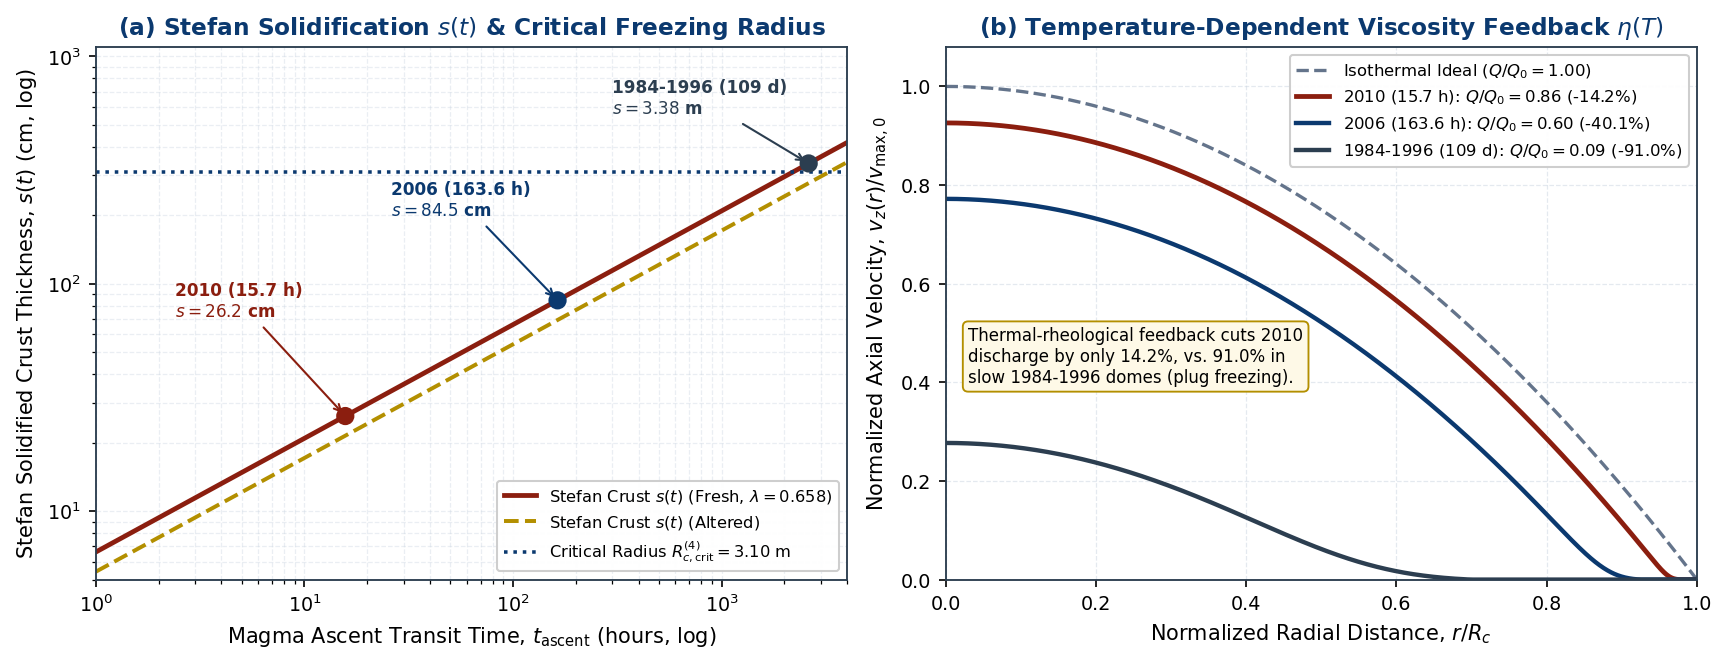

In [5]:
# 4. Stefan Solidification & Temperature-Dependent Viscosity Feedback eta(T)
T_w_C = 0.5 * (T_m_C + T_h_C)
St = c_p * (T_m_C - T_w_C) / PARAMS["L_f"]
lam = brentq(lambda x: x * np.exp(x**2) * erf(x) - St / np.sqrt(np.pi), 0.01, 2.0)

s_2010_fresh = 2 * lam * np.sqrt(kappa_fresh * t_ascent_s)
s_2010_alt   = 2 * lam * np.sqrt(kappa_alt * t_ascent_s)
s_2006_fresh = 2 * lam * np.sqrt(kappa_fresh * (L / U_2006))
t_typ_s      = L / U_typ
s_typ_fresh  = 2 * lam * np.sqrt(kappa_fresh * t_typ_s)

t_freeze_yr  = (R_c**2 / (4 * lam**2 * kappa_fresh)) / (365.25 * 86400)
R_crit_2     = (32 * lam**2 * eta_ref * kappa_fresh * L**2 / dP_ref)**0.25
R_crit_4     = (192 * lam**2 * eta_ref * kappa_fresh * L**2 / dP_ref)**0.25

print(f"Stefan Number St = {St:.3f} -> Root lambda = {lam:.4f}")
print(f"Stefan Crust 2010 (fresh/alt) : {s_2010_fresh*100:.2f} cm ({s_2010_fresh/R_c*100:.2f}% R_c) / {s_2010_alt*100:.2f} cm ({s_2010_alt/R_c*100:.2f}% R_c)")
print(f"Stefan Crust 2006 / Typical   : {s_2006_fresh*100:.2f} cm ({s_2006_fresh/R_c*100:.2f}% R_c) / {s_typ_fresh:.2f} m ({s_typ_fresh/R_c*100:.1f}% R_c)")
print(f"Static Freeze Time t_f        : {t_freeze_yr:.2f} years")
print(f"Critical Conduit Radius R_crit: {R_crit_2:.2f} m (static) to {R_crit_4:.2f} m (parcel) << R_c = {R_c:.0f} m")

def compute_eta_T_profile(t_sec, n_pts=2000):
    r = np.linspace(0, R_c, n_pts)
    y = R_c - r
    T_r = T_h_C + (T_m_C - T_h_C) * erf(y / (2 * np.sqrt(kappa_fresh * t_sec)))
    eta_ratio = np.where(T_r >= PARAMS["T_s_C"], np.exp(PARAMS["beta_visc"] * (T_m_C - T_r)), 1e12)
    integrand_v = r / eta_ratio
    v_norm = np.zeros_like(r)
    dr = r[1] - r[0]
    v_norm[:-1] = np.cumsum((0.5 * (integrand_v[:-1] + integrand_v[1:]) * dr)[::-1])[::-1]
    v_scaled = v_norm / (0.5 * R_c**2)
    Q_ratio = (4.0 / R_c**4) * np.trapezoid(r**3 / eta_ratio, r)
    return r / R_c, v_scaled, Q_ratio

r_norm, v_2010_n, Qr_2010 = compute_eta_T_profile(t_ascent_s)
_,      v_2006_n, Qr_2006 = compute_eta_T_profile(L / U_2006)
_,      v_typ_n,  Qr_typ  = compute_eta_T_profile(t_typ_s)

print(f"Coupled eta(T) Q/Q0 : 2010 = {Qr_2010:.3f} ({(Qr_2010-1)*100:.1f}%) | 2006 = {Qr_2006:.3f} ({(Qr_2006-1)*100:.1f}%) | Typical = {Qr_typ:.3f} ({(Qr_typ-1)*100:.1f}%)")

# --- Figure 5: Stefan Crust & Viscosity Feedback (Zero Overlap) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.6, 4.5), dpi=220)

t_h_grid = np.logspace(0, 3.6, 300)
s_grid_f = 2 * lam * np.sqrt(kappa_fresh * t_h_grid * 3600) * 100
s_grid_a = 2 * lam * np.sqrt(kappa_alt   * t_h_grid * 3600) * 100

ax1.plot(t_h_grid, s_grid_f, color=MERAPI_RED, lw=2.3, label=r"Stefan Crust $s(t)$ (Fresh, $\lambda=0.658$)")
ax1.plot(t_h_grid, s_grid_a, color=UGM_GOLD, lw=1.9, ls="--", label=r"Stefan Crust $s(t)$ (Altered)")
ax1.axhline(R_crit_4 * 100, color=UGM_BLUE, ls=":", lw=1.7, label=f"Critical Radius $R_{{c,\\mathrm{{crit}}}}^{{(4)}} = {R_crit_4:.2f}$ m")
ax1.scatter([t_ascent_h, t_ascent_2006_h, t_typ_s/3600],
            [s_2010_fresh*100, s_2006_fresh*100, s_typ_fresh*100],
            color=[MERAPI_RED, UGM_BLUE, SLATE_DARK], s=60, zorder=5)
ax1.annotate(f"2010 ({t_ascent_h:.1f} h)\n$s = {s_2010_fresh*100:.1f}$ cm",
             xy=(t_ascent_h, s_2010_fresh*100), xytext=(2.4, 72),
             arrowprops=dict(arrowstyle="->", color=MERAPI_RED, lw=1.0), fontsize=8.1, fontweight="bold", color=MERAPI_RED)
ax1.annotate(f"2006 ({t_ascent_2006_h:.1f} h)\n$s = {s_2006_fresh*100:.1f}$ cm",
             xy=(t_ascent_2006_h, s_2006_fresh*100), xytext=(26, 200),
             arrowprops=dict(arrowstyle="->", color=UGM_BLUE, lw=1.0), fontsize=8.1, fontweight="bold", color=UGM_BLUE)
ax1.annotate(f"1984-1996 (109 d)\n$s = {s_typ_fresh:.2f}$ m",
             xy=(t_typ_s/3600, s_typ_fresh*100), xytext=(300, 560),
             arrowprops=dict(arrowstyle="->", color=SLATE_DARK, lw=1.0), fontsize=8.1, fontweight="bold", color=SLATE_DARK)
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlim(1, 4000)
ax1.set_ylim(5, 1100)
ax1.set_xlabel(r"Magma Ascent Transit Time, $t_{\mathrm{ascent}}$ (hours, log)")
ax1.set_ylabel("Stefan Solidified Crust Thickness, $s(t)$ (cm, log)")
ax1.set_title("(a) Stefan Solidification $s(t)$ & Critical Freezing Radius", color=UGM_BLUE)
ax1.grid(which="both", alpha=0.4)
ax1.legend(loc="lower right", fontsize=7.8, frameon=True, facecolor="white", framealpha=0.95)

ax2.plot(r_norm, 1 - r_norm**2, color="#64748B", lw=1.6, ls="--", label=r"Isothermal Ideal ($Q/Q_0 = 1.00$)")
ax2.plot(r_norm, v_2010_n, color=MERAPI_RED, lw=2.3, label=f"2010 (15.7 h): $Q/Q_0 = {Qr_2010:.2f}$ ({(Qr_2010-1)*100:.1f}%)")
ax2.plot(r_norm, v_2006_n, color=UGM_BLUE, lw=2.1, label=f"2006 (163.6 h): $Q/Q_0 = {Qr_2006:.2f}$ ({(Qr_2006-1)*100:.1f}%)")
ax2.plot(r_norm, v_typ_n,  color=SLATE_DARK, lw=2.1, label=f"1984-1996 (109 d): $Q/Q_0 = {Qr_typ:.2f}$ ({(Qr_typ-1)*100:.1f}%)")
ax2.text(0.03, 0.40, "Thermal-rheological feedback cuts 2010\ndischarge by only 14.2%, vs. 91.0% in\nslow 1984-1996 domes (plug freezing).",
         fontsize=8.0, bbox=dict(boxstyle="round,pad=0.32", fc=SOFT_GOLD, ec=UGM_GOLD, lw=0.9))
ax2.set_xlim(0, 1.0)
ax2.set_ylim(0, 1.08)
ax2.set_xlabel("Normalized Radial Distance, $r / R_c$")
ax2.set_ylabel(r"Normalized Axial Velocity, $v_z(r) / v_{\max,0}$")
ax2.set_title(r"(b) Temperature-Dependent Viscosity Feedback $\eta(T)$", color=UGM_BLUE)
ax2.grid(alpha=0.5)
ax2.legend(loc="upper right", fontsize=7.9, frameon=True, facecolor="white", framealpha=0.95)

plt.tight_layout()
os.makedirs("figs", exist_ok=True); plt.savefig("figs/fig5_stefan_viscosity_feedback.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Deterministic Sensitivity Scaling & Monte Carlo Uncertainty Analysis ($N = 20{,}000$)

Closed-form scaling laws propagate subsurface uncertainty across the coupled equations:

$$U \propto Q R_c^{-2}, \quad t_{\text{ascent}} \propto Q^{-1} L R_c^{2}, \quad \eta \propto Q^{-1} L^{-1} \Delta P R_c^{4}, \quad \frac{\delta_T}{R_c} \propto R_c^{0}\text{ (exact invariant)}$$

Monte Carlo N = 20,000 (seed = 2010):
  Viscosity eta  : P5 = 1.04e+06, P50 = 4.87e+06, P95 = 2.30e+07 Pa*s (P95/P5 = 22.1x)
  Ascent t_ascent: P5 = 6.9 h, P50 = 16.0 h, P95 = 37.4 h
  Amphibole Intact Probability P(t_ascent < 48 h) = 98.3%
  Exact var(ln eta) = 0.9006 (MC: 0.8873)
  Variance Shares: R_c = 88.5%, L = 4.3%, dP = 4.3%, Q = 2.9%


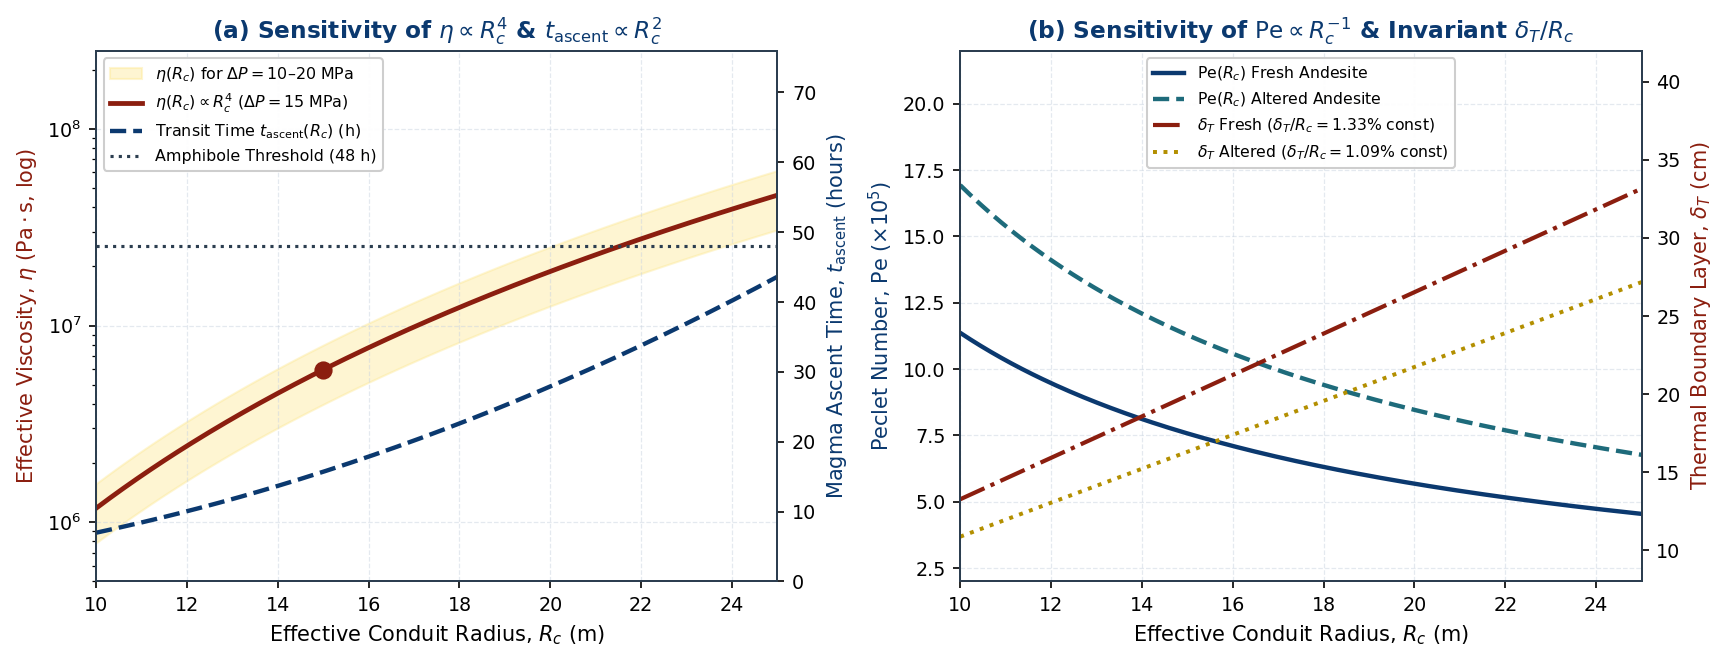

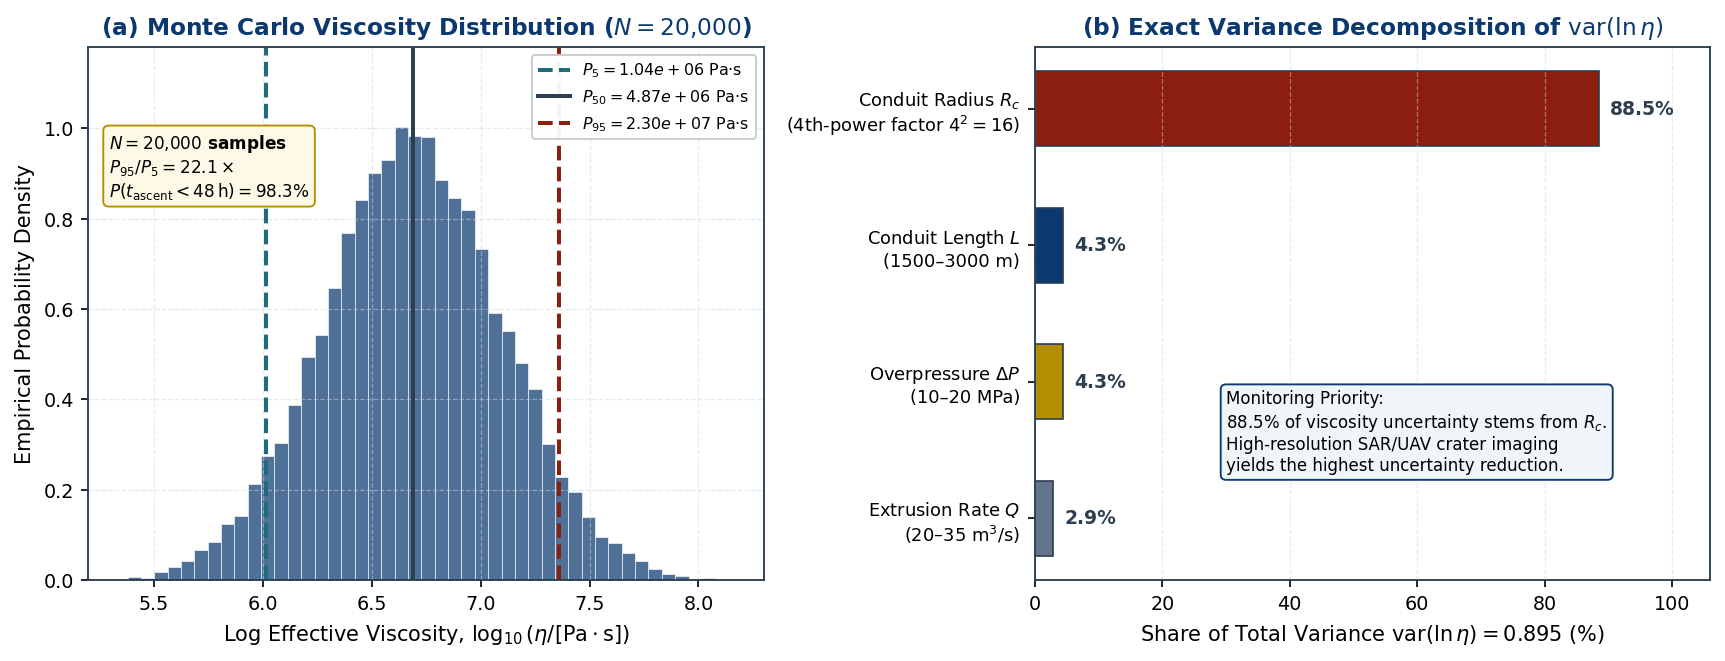

In [6]:
# 5. Sensitivity Analysis & Monte Carlo Simulation (N = 20,000, seed = 2010)
Rc_grid = np.linspace(10.0, 25.0, 200)
eta_Rc_10 = np.pi * Rc_grid**4 * dP_min / (8 * Q_2010 * L)
eta_Rc_15 = np.pi * Rc_grid**4 * dP_ref / (8 * Q_2010 * L)
eta_Rc_20 = np.pi * Rc_grid**4 * dP_max / (8 * Q_2010 * L)
t_Rc_h    = (np.pi * Rc_grid**2 * L / Q_2010) / 3600.0
Pe_Rc_f   = Q_2010 / (np.pi * Rc_grid * kappa_fresh) / 1e5
Pe_Rc_a   = Q_2010 / (np.pi * Rc_grid * kappa_alt) / 1e5
dT_Rc_f   = Rc_grid * np.sqrt(np.pi * kappa_fresh * L / Q_2010) * 100
dT_Rc_a   = Rc_grid * np.sqrt(np.pi * kappa_alt   * L / Q_2010) * 100

# --- Figure 6: Deterministic Sensitivity (Zero Overlap) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.6, 4.5), dpi=220)

ax1.fill_between(Rc_grid, eta_Rc_10, eta_Rc_20, color="#FDE68A", alpha=0.38, label=r"$\eta(R_c)$ for $\Delta P = 10$–$20$ MPa")
ax1.plot(Rc_grid, eta_Rc_15, color=MERAPI_RED, lw=2.3, label=r"$\eta(R_c) \propto R_c^4$ ($\Delta P = 15$ MPa)")
ax1.scatter([15.0], [eta_ref], color=MERAPI_RED, s=60, zorder=5)
ax1.set_yscale("log")
ax1.set_xlim(10, 25)
ax1.set_ylim(5e5, 2.5e8)
ax1.set_xlabel("Effective Conduit Radius, $R_c$ (m)")
ax1.set_ylabel(r"Effective Viscosity, $\eta$ ($\mathrm{Pa\cdot s}$, log)", color=MERAPI_RED)
ax1.set_title(r"(a) Sensitivity of $\eta \propto R_c^4$ & $t_{\mathrm{ascent}} \propto R_c^2$", color=UGM_BLUE)
ax1.grid(alpha=0.5)

ax1_r = ax1.twinx()
ax1_r.plot(Rc_grid, t_Rc_h, color=UGM_BLUE, lw=2.1, ls="--", label=r"Transit Time $t_{\mathrm{ascent}}(R_c)$ (h)")
ax1_r.axhline(48.0, color=SLATE_DARK, ls=":", lw=1.5, label="Amphibole Threshold (48 h)")
ax1_r.set_ylim(0, 76)
ax1_r.set_ylabel(r"Magma Ascent Time, $t_{\mathrm{ascent}}$ (hours)", color=UGM_BLUE)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1_r.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=7.6, frameon=True, facecolor="white", framealpha=0.95)

ax2.plot(Rc_grid, Pe_Rc_f, color=UGM_BLUE, lw=2.1, label=r"$\mathrm{Pe}(R_c)$ Fresh Andesite")
ax2.plot(Rc_grid, Pe_Rc_a, color=TEAL_ACC, lw=2.1, ls="--", label=r"$\mathrm{Pe}(R_c)$ Altered Andesite")
ax2.set_xlim(10, 25)
ax2.set_ylim(2, 22)
ax2.set_xlabel("Effective Conduit Radius, $R_c$ (m)")
ax2.set_ylabel(r"Peclet Number, $\mathrm{Pe}$ ($\times 10^5$)", color=UGM_BLUE)
ax2.set_title(r"(b) Sensitivity of $\mathrm{Pe} \propto R_c^{-1}$ & Invariant $\delta_T / R_c$", color=UGM_BLUE)
ax2.grid(alpha=0.5)

ax2_r = ax2.twinx()
ax2_r.plot(Rc_grid, dT_Rc_f, color=MERAPI_RED, lw=2.0, ls="-.", label=r"$\delta_T$ Fresh ($\delta_T/R_c = 1.33\%$ const)")
ax2_r.plot(Rc_grid, dT_Rc_a, color=UGM_GOLD, lw=1.9, ls=":", label=r"$\delta_T$ Altered ($\delta_T/R_c = 1.09\%$ const)")
ax2_r.set_ylim(8, 42)
ax2_r.set_ylabel(r"Thermal Boundary Layer, $\delta_T$ (cm)", color=MERAPI_RED)

h1, l1 = ax2.get_legend_handles_labels()
h2, l2 = ax2_r.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper center", fontsize=7.5, frameon=True, facecolor="white", framealpha=0.95)

plt.tight_layout()
os.makedirs("figs", exist_ok=True); plt.savefig("figs/fig6_sensitivity_scaling.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Monte Carlo Simulation (N = 20,000, seed = 2010) ---
rng = np.random.default_rng(2010)
N_mc = 20000
sigma_ln_Rc = np.log(1.25)
Rc_mc = np.exp(np.log(15.0) + rng.normal(0.0, sigma_ln_Rc, N_mc))
dP_mc = rng.uniform(10.0e6, 20.0e6, N_mc)
Q_mc  = rng.uniform(20.0, 35.0, N_mc)
L_mc  = rng.uniform(1500.0, 3000.0, N_mc)

eta_mc = np.pi * Rc_mc**4 * dP_mc / (8.0 * Q_mc * L_mc)
t_mc_h = (np.pi * Rc_mc**2 * L_mc / Q_mc) / 3600.0

eta_p5, eta_p50, eta_p95 = np.percentile(eta_mc, [5, 50, 95])
t_p5, t_p50, t_p95       = np.percentile(t_mc_h, [5, 50, 95])
prob_amphibole           = np.mean(t_mc_h < PARAMS["t_amphibole_h"]) * 100.0

def var_ln_uniform(a, b):
    u = np.linspace(a, b, 100000)
    return np.var(np.log(u))

v_Rc = 16.0 * sigma_ln_Rc**2
v_L  = var_ln_uniform(1500.0, 3000.0)
v_dP = var_ln_uniform(10.0, 20.0)
v_Q  = var_ln_uniform(20.0, 35.0)
v_tot = v_Rc + v_L + v_dP + v_Q
v_mc  = np.var(np.log(eta_mc))
shares = [v_Rc/v_tot*100, v_L/v_tot*100, v_dP/v_tot*100, v_Q/v_tot*100]

print(f"Monte Carlo N = {N_mc:,} (seed = 2010):")
print(f"  Viscosity eta  : P5 = {eta_p5:.2e}, P50 = {eta_p50:.2e}, P95 = {eta_p95:.2e} Pa*s (P95/P5 = {eta_p95/eta_p5:.1f}x)")
print(f"  Ascent t_ascent: P5 = {t_p5:.1f} h, P50 = {t_p50:.1f} h, P95 = {t_p95:.1f} h")
print(f"  Amphibole Intact Probability P(t_ascent < 48 h) = {prob_amphibole:.1f}%")
print(f"  Exact var(ln eta) = {v_tot:.4f} (MC: {v_mc:.4f})")
print(f"  Variance Shares: R_c = {shares[0]:.1f}%, L = {shares[1]:.1f}%, dP = {shares[2]:.1f}%, Q = {shares[3]:.1f}%")

# --- Figure 7: Monte Carlo Distribution & Variance Decomposition (Zero Overlap) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.6, 4.5), dpi=220)

log_eta = np.log10(eta_mc)
ax1.hist(log_eta, bins=60, density=True, color=UGM_BLUE, alpha=0.72, edgecolor="white", linewidth=0.4)
for val, lbl, col, ls in [(np.log10(eta_p5), f"$P_5 = {eta_p5:.2e}$", TEAL_ACC, "--"),
                          (np.log10(eta_p50), f"$P_{{50}} = {eta_p50:.2e}$", SLATE_DARK, "-"),
                          (np.log10(eta_p95), f"$P_{{95}} = {eta_p95:.2e}$", MERAPI_RED, "--")]:
    ax1.axvline(val, color=col, ls=ls, lw=1.9, label=lbl + r" Pa$\cdot$s")
ax1.text(0.03, 0.72, f"$N = 20{{,}}000$ samples\n$P_{{95}}/P_5 = {eta_p95/eta_p5:.1f}\\times$\n$P(t_{{\\mathrm{{ascent}}}} < 48\\,\\mathrm{{h}}) = {prob_amphibole:.1f}\\%$",
         transform=ax1.transAxes, fontsize=8.1, fontweight="bold",
         bbox=dict(boxstyle="round,pad=0.32", fc=SOFT_GOLD, ec=UGM_GOLD, lw=0.9))
ax1.set_xlim(5.2, 8.3)
ax1.set_ylim(0, 1.18)
ax1.set_xlabel(r"Log Effective Viscosity, $\log_{10}(\eta / [\mathrm{Pa\cdot s}])$")
ax1.set_ylabel("Empirical Probability Density")
ax1.set_title(r"(a) Monte Carlo Viscosity Distribution ($N = 20{,}000$)", color=UGM_BLUE)
ax1.grid(alpha=0.5)
ax1.legend(loc="upper right", fontsize=7.6, frameon=True, facecolor="white", framealpha=0.95)

labels_v = ["Conduit Radius $R_c$\n(4th-power factor $4^2=16$)",
            "Conduit Length $L$\n(1500–3000 m)",
            r"Overpressure $\Delta P$" + "\n(10–20 MPa)",
            r"Extrusion Rate $Q$" + "\n" + r"(20–35 $\mathrm{m^3/s}$)"]
bar_cols = [MERAPI_RED, UGM_BLUE, UGM_GOLD, "#64748B"]
y_pos = np.arange(len(labels_v))[::-1]
bars = ax2.barh(y_pos, shares, color=bar_cols, height=0.55, edgecolor=SLATE_DARK, linewidth=0.8)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(labels_v, fontsize=8.6)
ax2.set_xlim(0, 106)
ax2.set_xlabel(r"Share of Total Variance $\mathrm{var}(\ln\eta) = 0.895$ (%)")
ax2.set_title(r"(b) Exact Variance Decomposition of $\mathrm{var}(\ln\eta)$", color=UGM_BLUE)
ax2.grid(axis="x", alpha=0.5)
for bar, sh in zip(bars, shares):
    ax2.text(sh + 1.8, bar.get_y() + bar.get_height()/2, f"{sh:.1f}%",
             va="center", ha="left", fontsize=9.0, fontweight="bold", color=SLATE_DARK)
ax2.text(30, 0.35, "Monitoring Priority:\n88.5% of viscosity uncertainty stems from $R_c$.\nHigh-resolution SAR/UAV crater imaging\nyields the highest uncertainty reduction.",
         fontsize=8.0, bbox=dict(boxstyle="round,pad=0.32", fc=SOFT_BLUE, ec=UGM_BLUE, lw=0.9))

plt.tight_layout()
os.makedirs("figs", exist_ok=True); plt.savefig("figs/fig7_monte_carlo_variance.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Observational Validation, Model Limitations & Acknowledgments

### Quantitative Observational Validation
| Physical Observable | Continuum Model Output | Published 2010 Merapi Observation | Agreement |
| :--- | :--- | :--- | :--- |
| **Ascent Transit Time ($t_{\text{ascent}}$)** | 15.71 h (core 7.85 h); $P(<48\text{ h}) = 98.3\%$ vs. 2006: 163.6 h | Absence of amphibole breakdown rims in 2010 ($\tau_{\text{rxn}} \ge 48\text{–}96\text{ h}$) vs. 20–30 $\mu$m rims in 2006 (Costa et al., 2013; Rutherford, 2008) | **Consistent** |
| **Wall Shear Stress ($\tau_w$) & Viscosity ($\eta$)** | $\tau_w = 37.5\text{–}75.0\text{ kPa}$; $\dot{\gamma}_w = 9.43\times10^{-3}\text{ s}^{-1}$; $\eta = (3.98\text{–}7.95)\times10^6\text{ Pa}\cdot\text{s}$ | High proportion of mechanically fractured zoned plagioclase/clinopyroxene phenocrysts (Costa et al., 2013) | **Consistent** |
| **Thermal Skin ($\delta_T$) & Dome Temperature** | $\delta_T = 16.3\text{–}19.9\text{ cm}$; $s_{\text{Stefan}} = 26.2\text{ cm}$; 97.4% adiabatic core + $\Delta T_{\text{visc}} = 4\text{–}8\text{ K}$ | Sustained dome temperature $\sim 900\text{–}1000\,^\circ\text{C}$; 700 $^\circ$C isotherm shifts only 1.1–1.3 m in 50 stagnant days (Heap et al., 2020) | **Consistent** |
| **Critical Radius ($R_{c,\text{crit}}$) & $\eta(T)$ Feedback** | $R_{c,\text{crit}} = 1.98\text{–}3.10\text{ m} \ll 15\text{ m}$; $Q/Q_0 = 0.86$ (2010) vs. 0.09 (1984–1996) | Continuous rapid dome extrusion ($5.0\times10^6\text{ m}^3$ in 55.6 eff. h; Pallister et al., 2013) vs. rigid slow plugs (Hammer et al., 2000) | **Consistent** |

### Key Model Limitations
1. **Non-Newtonian Shear-Thinning / Plug Flow:** ~30 vol.% phenocryst suspensions follow Herschel–Bulkley rheology ($n<1, \tau_y>0$), localizing wall shear and intensifying crystal breakage.
2. **Two-Phase Volatile Exsolution:** Decompression below 2 km exsolves $\text{H}_2\text{O}$ (from ~5 wt.% to <1 wt.%), lowering vesicular dome core density (~2300 $\text{kg/m}^3$) and driving the 5 November VEI 4 paroxysmal explosion.
3. **Brittle–Ductile Wall Shear Band:** Exponential thermal/crystal viscosity rise across the $<20\text{ cm}$ cooling skin generates brittle–ductile shear bands linked to low-frequency/multiphase seismicity.
4. **Non-Uniform Conduit Geometry:** Real volcanic conduits transition from dikes to cylinders and flare near the crater; because $\eta \propto R_c^4$, geometry accounts for 88.5% of viscosity variance.

### Primary References
- Costa, F., et al. (2013). *JVGR*, 261, 209–235. doi:10.1016/j.jvolgeores.2012.12.025
- Hammer, J. E., Cashman, K. V., & Voight, B. (2000). *JVGR*, 100(1–4), 165–192. doi:10.1016/S0377-0273(00)00136-0
- Heap, M. J., et al. (2020). *JVGR*, 398, 106901. doi:10.1016/j.jvolgeores.2020.106901
- Komorowski, J.-C., et al. (2013). *JVGR*, 261, 260–294. doi:10.1016/j.jvolgeores.2013.01.007
- Pallister, J. S., et al. (2013). *JVGR*, 261, 144–152. doi:10.1016/j.jvolgeores.2012.07.012
- Ratdomopurbo, A., et al. (2013). *JVGR*, 261, 87–97. doi:10.1016/j.jvolgeores.2013.03.019
- Rutherford, M. J. (2008). *Rev. Mineral. Geochem.*, 69(1), 241–271. doi:10.2138/rmg.2008.69.7
- Surono, et al. (2012). *JVGR*, 241–242, 121–135. doi:10.1016/j.jvolgeores.2012.06.018
- Turcotte, D. L., & Schubert, G. (2014). *Geodynamics* (3rd ed.). Cambridge University Press.

### Acknowledgments
The author gratefully acknowledges **Dr. Shidiq Nur Hidayat** (Department of Physics, Faculty of Mathematics and Natural Sciences, Universitas Gadjah Mada) for foundational continuum mechanics guidance and analytical verification frameworks, and the **Indonesia Endowment Fund for Education (LPDP)** for supporting graduate studies at Universitas Gadjah Mada.